# Soluzione — Screening diagnostico con scikit-learn

Questo notebook risolve, punto per punto, l'*Esercizio omnicomprensivo — Screening diagnostico con scikit-learn*.
Per ogni punto trovi: **cosa chiede**, **come lo risolviamo** (con codice commentato) e **cosa significa** il risultato.

Convenzione del dataset: `0 = maligno`, `1 = benigno`. La classe da individuare è la **0**: in tutte le metriche usiamo `pos_label=0`.

| Punto | Argomento | Moduli |
| --- | --- | --- |
| 1 | Definizione del problema | 1.1, 1.2 |
| 2 | Esplorazione dei dati | 1.2, 1.4 |
| 3 | Divisione train / validation / test | 1.5, 1.7, 2.2, 2.5 |
| 4 | Baseline con `DummyClassifier` | 2.5 |
| 5 | KNN senza scaling | 1.5, 1.6 |
| 6 | Scaling e regola d'oro | 2.1, 2.2 |
| 7 | Scelta di k e curva di complessità | 1.6, 1.7 |
| 8 | Albero di decisione | 2.4, 1.7 |
| 9 | Valutazione finale sul test set | 2.5, 1.7 |

## Setup
Importiamo le librerie e fissiamo `RANDOM_STATE = 42`: così gli split e l'albero danno sempre lo stesso risultato.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import load_breast_cancer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree

# Seme unico per tutto il notebook: rende riproducibili split e alberi
RANDOM_STATE = 42
print("scikit-learn:", sklearn.__version__, "| pandas:", pd.__version__)

scikit-learn: 1.9.1 | pandas: 3.1.0


## Punto 1 — Definizione del problema

- **Tipo di apprendimento: supervisionato.** Per ogni paziente conosciamo già l'esito (maligno o benigno) e il modello impara da esempi etichettati.
- **Tipo di problema: classificazione binaria.** La risposta è una delle due classi, `0` o `1`.
- **Target:** la colonna `target`, che chiamiamo `y`. Le 30 misure del nodulo sono le **feature**, che chiamiamo `X`.

## Punto 2 — Esplorazione dei dati

### 2.1 Caricamento con `as_frame=True`
`load_breast_cancer` restituisce un oggetto `Bunch` (un dizionario con attributi). Con `as_frame=True` i dati sono un DataFrame pandas, quindi le colonne hanno nomi leggibili invece di essere solo numeri.

In [2]:
d = load_breast_cancer(as_frame=True)
# d.frame è la tabella completa: le 30 feature più la colonna target
df = d.frame

print("Forma di X (d.data):   ", d.data.shape)
print("Forma di y (d.target): ", d.target.shape)
print("Nomi delle feature:", [str(nome) for nome in d.feature_names])
print("Nomi delle classi:", [str(nome) for nome in d.target_names])  # posizione 0 -> 'malignant', 1 -> 'benign'

Forma di X (d.data):    (569, 30)
Forma di y (d.target):  (569,)
Nomi delle feature: ['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension']
Nomi delle classi: ['malignant', 'benign']


### 2.2 Prime 5 righe

In [3]:
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


### 2.3 Descrizione del dataset
Il `DESCR` è molto lungo: stampiamo solo le righe che ci servono (origine e struttura dei dati).

In [4]:
for riga in d.DESCR.splitlines():
    if riga.strip().startswith((":Number of", ":Donor", ":Date")):
        print(riga.strip())

# Le feature sono le misure ricavate dall'immagine digitalizzata di un nodulo
print()
print(d.DESCR[d.DESCR.find("The mean, standard error"):][:260])

:Number of Instances: 569
:Number of Attributes: 30 numeric, predictive attributes and the class
:Donor: Nick Street
:Date: November, 1995

The mean, standard error, and "worst" or largest (mean of the three
    worst/largest values) of these features were computed for each image,
    resulting in 30 features.  For instance, field 0 is Mean Radius, field
    10 is Radius SE, field 20 is Worst Radi


**Lettura del DESCR:**
- **Origine:** dataset *Wisconsin Diagnostic Breast Cancer*, donato da Nick Street nel novembre 1995.
- **Misure:** derivano da un'immagine digitalizzata di un aspirato con ago sottile (FNA) di un nodulo mammario.
- **Struttura:** 10 misure base (raggio, texture, perimetro, area, ...), ciascuna in tre versioni: *media*, *errore standard* (`SE`) e *worst* (media delle tre misure più grandi). Da qui le 30 feature.
- **Unità di misura:** il DESCR non riporta unità fisiche esplicite: sono quantità numeriche calcolate sull'immagine.

### 2.4 Quanti campioni per classe?
`value_counts()` conta le righe per classe. Usiamo i nomi delle classi invece dei numeri 0 e 1.

In [5]:
conteggio = df["target"].map(dict(enumerate(d.target_names))).value_counts()
print(conteggio)
print()
print((conteggio / conteggio.sum()).round(3))  # le stesse quantità in percentuale

target
benign       357
malignant    212
Name: count, dtype: int64

target
benign       0.627
malignant    0.373
Name: count, dtype: float64


**Le classi sono bilanciate?** Quasi: circa il 63% benigni e il 37% maligni. Non è uno sbilanciamento grave, ma basta a rendere fuorviante l'accuratezza: un modello che dicesse sempre «benigno» avrebbe già circa il 63% di risposte giuste. Ci torneremo al punto 4.

### 2.5 Minimo e massimo delle feature
`describe()` riassume ogni feature. Ci interessa l'intervallo di valori (massimo meno minimo) per capire quali feature hanno la scala più grande e quale quella più piccola.

In [6]:
feature = df.drop(columns="target")  # solo le feature, senza il target
print(feature.describe().T[["min", "max"]].round(4))

                              min        max
mean radius                6.9810    28.1100
mean texture               9.7100    39.2800
mean perimeter            43.7900   188.5000
mean area                143.5000  2501.0000
mean smoothness            0.0526     0.1634
mean compactness           0.0194     0.3454
mean concavity             0.0000     0.4268
mean concave points        0.0000     0.2012
mean symmetry              0.1060     0.3040
mean fractal dimension     0.0500     0.0974
radius error               0.1115     2.8730
texture error              0.3602     4.8850
perimeter error            0.7570    21.9800
area error                 6.8020   542.2000
smoothness error           0.0017     0.0311
compactness error          0.0023     0.1354
concavity error            0.0000     0.3960
concave points error       0.0000     0.0528
symmetry error             0.0079     0.0790
fractal dimension error    0.0009     0.0298
worst radius               7.9300    36.0400
worst text

In [7]:
ampiezza = feature.max() - feature.min()  # quanto è larga la scala di ogni feature

print("Scala più grande:", ampiezza.idxmax(), "| range =", round(ampiezza.max(), 2))
print("Scala più piccola:", ampiezza.idxmin(), "| range =", round(ampiezza.min(), 4))

Scala più grande: worst area | range = 4068.8
Scala più piccola: fractal dimension error | range = 0.0289


**Perché conta?** La feature con la scala più grande (`worst area`, valori fino a 4254) ha differenze di migliaia di unità, mentre la più piccola (`fractal dimension error`, valori tra 0.001 e 0.03) varia di pochi millesimi. Il KNN calcola le **distanze** tra pazienti: una feature così sbilanciata finisce per dominare il calcolo. Lo vedremo al punto 5 e lo correggeremo al punto 6.

### 2.6 Separazione di `X` e `y`
Il target non deve restare dentro `X`: altrimenti il modello «vedrebbe la risposta». Lo verifichiamo con un `assert`.

In [8]:
X = d.data  # solo le 30 feature
y = d.target  # solo il target

assert "target" not in X.columns  # controllo: il target non è finito dentro X
print("X:", X.shape, "| y:", y.shape)

X: (569, 30) | y: (569,)


## Punto 3 — Divisione dei dati

Servono **tre insiemi** con ruoli diversi:
- **training (60%)**: il modello impara da qui;
- **validation (20%)**: scegliamo k, la profondità dell'albero e lo scaler;
- **test (20%)**: stima finale, usata una sola volta al punto 9.

Con due chiamate a `train_test_split`: la prima stacca il test (20%); la seconda divide l'80% rimasto in training e validation. Il `test_size=0.25` della seconda chiamata, applicato all'80%, dà esattamente il 20% del totale. `stratify=y` mantiene in ogni insieme la stessa proporzione di maligni.

In [9]:
# Primo split: stacchiamo il test set (20%) e lo teniamo da parte fino al punto 9
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

# Secondo split: dall'80% rimasto ricaviamo training (60%) e validation (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=RANDOM_STATE
)

for nome, y_insieme in [("training", y_train), ("validation", y_val), ("test", y_test)]:
    print(f"{nome:<11} n = {len(y_insieme):>3}   maligni = {(y_insieme == 0).mean():.1%}")

training    n = 341   maligni = 37.2%
validation  n = 114   maligni = 37.7%
test        n = 114   maligni = 36.8%


La percentuale di maligni è praticamente uguale nei tre insiemi (circa 37%): è l'effetto di `stratify=y`.

## Punto 4 — Baseline

Prima di costruire un modello vero, fissiamo una **soglia minima**. Il `DummyClassifier` ignora le feature e predice sempre la classe più frequente nel training. Qualunque modello che non batte questa soglia non ha nessun valore.

In [10]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)  # impara solo qual è la classe più frequente
pred_dummy_val = dummy.predict(X_val)

print("Accuratezza validation:", round(accuracy_score(y_val, pred_dummy_val), 3))
# pos_label=0: la classe positiva è il maligno, quella che vogliamo individuare
# zero_division=0: se il modello non predice mai il maligno, la recall vale 0 invece di dare errore
print("Recall maligni (validation):",
      round(recall_score(y_val, pred_dummy_val, pos_label=0, zero_division=0), 3))

Accuratezza validation: 0.623
Recall maligni (validation): 0.0


**Commento.** Il dummy ottiene circa il 62% di accuratezza, ma una recall sui maligni pari a **0**: non individua nessun tumore maligno.

L'accuratezza da sola inganna perché le classi non sono perfettamente bilanciate: un numero alto può nascondere un modello inutile proprio sulla classe che conta. Per questo nel punto 9 guarderemo anche precision, recall e matrice di confusione.

## Punto 5 — Primo modello: KNN senza scaling

Il **KNN** (k-Nearest Neighbors) classifica un nuovo paziente così: cerca i `k` pazienti del training più vicini e assegna la classe più votata. Il `fit` non impara una formula: memorizza i dati.

La sequenza è sempre la stessa: `fit` → `predict` → `score`.

In [11]:
knn = KNeighborsClassifier(n_neighbors=5)  # k = 5 vicini
knn.fit(X_train, y_train)                   # memorizza i dati di training
pred_val = knn.predict(X_val)               # classifica il validation set

print("Accuratezza training:  ", round(knn.score(X_train, y_train), 3))
print("Accuratezza validation:", round(knn.score(X_val, y_val), 3))

Accuratezza training:   0.95
Accuratezza validation: 0.93


### 5.3 I vicini di un paziente

In [12]:
campione = X_val.iloc[[0]]  # un solo paziente del validation (DataFrame con una riga)
print("Classe vera del paziente:", d.target_names[y_val.iloc[0]])

# kneighbors: distanze dai 5 vicini più prossimi e la loro posizione nel training set
distanze, posizioni = knn.kneighbors(campione)
vicini = pd.DataFrame({
    "distanza": distanze[0].round(2),
    "posizione_nel_training": posizioni[0],
    "classe": [d.target_names[c] for c in y_train.iloc[posizioni[0]]],
})
print(vicini.to_string(index=False))

# predict_proba: frazione di voti per ciascuna classe tra i 5 vicini
print()
print("Probabilità [maligno, benigno]:", knn.predict_proba(campione)[0])

Classe vera del paziente: benign
 distanza  posizione_nel_training classe
    14.96                     240 benign
    21.08                     286 benign
    22.05                      14 benign
    25.06                     324 benign
    25.89                     162 benign

Probabilità [maligno, benigno]: [0. 1.]


Tutti e 5 i vicini sono benigni, quindi la probabilità è 0 per il maligno e 1 per il benigno. Con `k=5` la probabilità è sempre una frazione con denominatore 5 (0/5, 1/5, ..., 5/5).

### 5.4 Quale feature pesa di più nella distanza?

In [13]:
# Per il vicino più prossimo: quanto contribuisce ogni feature alla distanza?
vicino_piu_prossimo = X_train.iloc[posizioni[0][0]]
contributo = (campione.iloc[0] - vicino_piu_prossimo) ** 2  # differenza al quadrato per feature
quota = (contributo / contributo.sum()).sort_values(ascending=False)
print("Quota della distanza per le 5 feature più influenti:")
print(quota.head(5).round(3))

Quota della distanza per le 5 feature più influenti:
mean area          0.403
worst texture      0.145
worst area         0.121
mean texture       0.116
worst perimeter    0.114
dtype: float64


**Il problema.** La distanza euclidea è la somma delle differenze al quadrato. Una feature come `mean area` (che da sola pesa circa il 40% della distanza, come mostra l'output) varia di centinaia di unità, mentre `fractal dimension error` varia di millesimi: la prima pesa milioni di volte di più. Il KNN quindi «ascolta» quasi solo le feature grandi, e il risultato dipende dalle **unità di misura** scelte, non dall'informazione diagnostica. La soluzione è portare le feature sulla stessa scala.

## Punto 6 — Scaling e regola d'oro

**Regola d'oro:** ogni transformer (scaler) fa `fit` **solo sul training**, poi applica `transform` a training, validation e test. Se lo scaler vedesse anche validation o test, media e deviazione standard conterrebbero informazioni su dati che dovremmo ancora ignorare (*data leakage*) e la stima sarebbe troppo ottimistica.

### 6.1 Fit sul training, transform su tutti

In [14]:
scaler = StandardScaler()  # trasforma ogni feature in (x - media) / deviazione standard
scaler.fit(X_train)        # fit SOLO sul training: impara media e deviazione standard da qui

X_train_sc = scaler.transform(X_train)
X_val_sc = scaler.transform(X_val)
X_test_sc = scaler.transform(X_test)  # il test viene scalato ora, ma non è ancora usato per valutare

### 6.2 Verifica delle statistiche

In [15]:
# Sul training: media ≈ 0 e deviazione standard ≈ 1 per ogni colonna
print(f"Training - massimo |media| tra le colonne: {np.abs(X_train_sc.mean(axis=0)).max():.1e}")
print(f"Training - deviazione standard (min, max): "
      f"{X_train_sc.std(axis=0).min():.6f}, {X_train_sc.std(axis=0).max():.6f}")

# Sul validation la media NON è esattamente 0
print("Validation - media (prime 5 colonne):", X_val_sc.mean(axis=0)[:5].round(3))

Training - massimo |media| tra le colonne: 3.6e-15
Training - deviazione standard (min, max): 1.000000, 1.000000
Validation - media (prime 5 colonne): [ 0.042  0.056  0.024  0.024 -0.117]


**Perché la media del validation non è 0?** Lo scaler ha usato solo le statistiche del training, quindi applica la stessa trasformazione a un campione diverso. Il validation è un insieme di pazienti diversi, quindi la sua media può differire da quella del training. Se la media del validation fosse esattamente 0, significherebbe che lo scaler ha usato anche i suoi dati: sarebbe un errore.

### 6.3 Il KNN con i dati scalati

In [16]:
knn_sc = KNeighborsClassifier(n_neighbors=5).fit(X_train_sc, y_train)

print("KNN scalato (k=5) - training:  ", round(knn_sc.score(X_train_sc, y_train), 3))
print("KNN scalato (k=5) - validation:", round(knn_sc.score(X_val_sc, y_val), 3))
print("KNN non scalato (punto 5) - validation:", round(knn.score(X_val, y_val), 3))

KNN scalato (k=5) - training:   0.974
KNN scalato (k=5) - validation: 0.956
KNN non scalato (punto 5) - validation: 0.93


Lo scaling migliora l'accuratezza di validation del KNN: il modello ora confronta tutte le feature con lo stesso peso.

### 6.4 Confronto con `MinMaxScaler`

In [17]:
# MinMaxScaler porta ogni feature nell'intervallo [0, 1], usando min e max del training
minmax = MinMaxScaler().fit(X_train)
X_val_mm = minmax.transform(X_val)
knn_mm = KNeighborsClassifier(n_neighbors=5).fit(minmax.transform(X_train), y_train)

confronto = pd.DataFrame({
    "accuratezza validation (KNN, k=5)": {
        "nessuno scaling": knn.score(X_val, y_val),
        "StandardScaler": knn_sc.score(X_val_sc, y_val),
        "MinMaxScaler": knn_mm.score(X_val_mm, y_val),
    }
}).round(3)
print(confronto)

                 accuratezza validation (KNN, k=5)
nessuno scaling                              0.930
StandardScaler                               0.956
MinMaxScaler                                 0.956

Su questo dataset i due scaler danno lo stesso risultato. La differenza è di principio: `MinMaxScaler` usa min e max, quindi un solo valore anomalo (outlier) cambia tutta la scala; `StandardScaler` usa media e deviazione standard, più stabili con gli outlier. Per questo lo teniamo come scelta standard.

### 6.5 Quali modelli hanno bisogno dello scaling?

- **KNN: sì.** Lavora con le distanze, quindi la scala delle feature conta.
- **Albero di decisione: no.** Ogni divisione è una soglia su una singola feature. Lo scaling è una trasformazione monotona, quindi le decisioni non cambiano (lo verifichiamo al punto 8).
- **DummyClassifier: no.** Non guarda affatto le feature.

Anche la regressione logistica, le SVM e le reti neurali hanno bisogno dello scaling; non sono in questo esercizio.

## Punto 7 — Scelta di k e diagnosi del modello

Calcoliamo accuratezza su training e validation per i valori dispari di `k` da 1 a 41. I valori **dispari** evitano i pareggi di voto tra le due classi.

In [18]:
risultati = []
for k in range(1, 42, 2):
    modello = KNeighborsClassifier(n_neighbors=k).fit(X_train_sc, y_train)
    risultati.append({
        "k": k,
        "accuratezza_training": modello.score(X_train_sc, y_train),
        "accuratezza_validation": modello.score(X_val_sc, y_val),
    })
risultati = pd.DataFrame(risultati)
print(risultati.round(3).to_string(index=False))

 k  accuratezza_training  accuratezza_validation
 1                 1.000                   0.939
 3                 0.977                   0.965
 5                 0.974                   0.956
 7                 0.968                   0.956
 9                 0.974                   0.947
11                 0.971                   0.939
13                 0.971                   0.930
15                 0.968                   0.939
17                 0.968                   0.939
19                 0.965                   0.939
21                 0.962                   0.930
23                 0.956                   0.930
25                 0.956                   0.930
27                 0.956                   0.930
29                 0.950                   0.921
31                 0.950                   0.921
33                 0.953                   0.921
35                 0.953                   0.921
37                 0.947                   0.921
39                 0

### 7.2 Curva di complessità

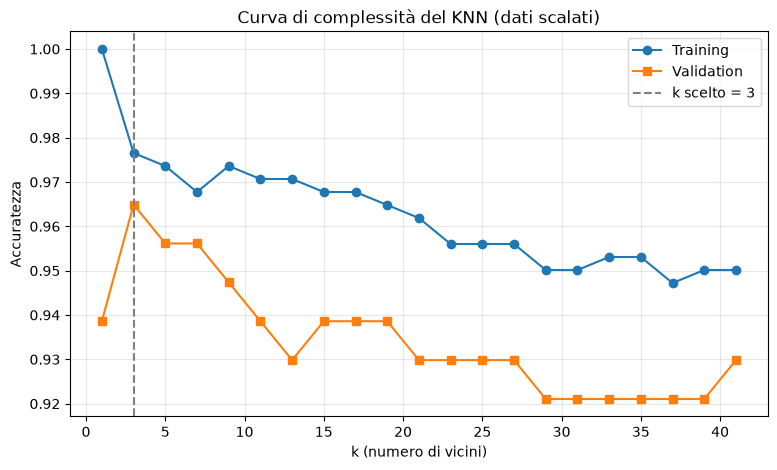

k scelto sul validation: 3


In [19]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(risultati["k"], risultati["accuratezza_training"], marker="o", label="Training")
ax.plot(risultati["k"], risultati["accuratezza_validation"], marker="s", label="Validation")

# Il k migliore è quello con la massima accuratezza sul VALIDATION, non sul training
riga_migliore = risultati["accuratezza_validation"].idxmax()
k_migliore = risultati.loc[riga_migliore, "k"]
ax.axvline(k_migliore, color="gray", linestyle="--", label=f"k scelto = {k_migliore}")

ax.set_title("Curva di complessità del KNN (dati scalati)")
ax.set_xlabel("k (numero di vicini)")
ax.set_ylabel("Accuratezza")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

print("k scelto sul validation:", k_migliore)

### 7.3 Overfitting e underfitting sul grafico

- **Overfitting (k piccolo, a sinistra).** Con k = 1 il training è al 100%: ogni paziente è il proprio vicino più prossimo, quindi il modello memorizza il rumore. Sul validation scende.
- **Underfitting (k grande, a destra).** Con k grande il modello diventa troppo «liscio»: ogni previsione è una media su troppi vicini e l'accuratezza cala su entrambi gli insiemi.
- **Zona buona.** Il picco di validation è a **k = 3**, con training ancora alto e distanza tra le due curve contenuta.

**Attenzione:** la differenza tra k = 3 (96.5%) e k = 5 (95.6%) corrisponde a **un solo paziente** su 114 nel validation. Un vantaggio così piccolo può essere rumore: non è una prova che k = 3 sia davvero migliore di k = 5.

## Punto 8 — Secondo modello: albero di decisione

Un albero di decisione costruisce una sequenza di domande del tipo «`worst area` ≤ 800?». Non usa distanze, quindi non ha bisogno dello scaling. La profondità massima (`max_depth`) controlla quanto l'albero può complicarsi: più è profondo, più rischia l'overfitting.

### 8.1 Confronto tra profondità
Addestriamo l'albero sui dati **non scalati**, come richiesto dall'esercizio.

In [20]:
profondita_possibili = [1, 2, 3, 5, 8, None]  # None = nessun limite: l'albero cresce finché le foglie sono pure

righe = []
for profondita in profondita_possibili:
    albero_p = DecisionTreeClassifier(max_depth=profondita, random_state=RANDOM_STATE)
    albero_p.fit(X_train, y_train)
    righe.append({
        "max_depth": "None" if profondita is None else profondita,
        "foglie": albero_p.get_n_leaves(),
        "accuratezza_training": albero_p.score(X_train, y_train),
        "accuratezza_validation": albero_p.score(X_val, y_val),
    })

tabella_alberi = pd.DataFrame(righe)
tabella_alberi.round(3)

,max_depth,foglie,accuratezza_training,accuratezza_validation
0,1,2,0.927,0.895
1,2,4,0.968,0.947
2,3,7,0.974,0.939
3,5,14,0.997,0.956
4,8,15,1.000,0.956
5,None,15,1.000,0.956


### 8.2 Scelta della profondità sul validation

In [21]:
massima_val = tabella_alberi["accuratezza_validation"].max()
profondita_a_massimo = tabella_alberi.loc[
    tabella_alberi["accuratezza_validation"] == massima_val, "max_depth"
].tolist()
print("Accuratezza validation massima:", round(massima_val, 3))
print("Profondità che la raggiungono:", profondita_a_massimo)

# Tra le profondità a pari merito scegliamo la più semplice
PROFONDITA_SCELTA = 5

Accuratezza validation massima: 0.956
Profondità che la raggiungono: [5, 8, 'None']


**Motivazione.** Profondità 5, 8 e `None` ottengono la stessa accuratezza di validation (95.6%). Le profondità 8 e `None` arrivano però al 100% sul training, cioè memorizzano il training set (overfitting). Tra i pari merito scegliamo la profondità **5**: è la più semplice, con 14 foglie, e l'accuratezza è la stessa. Con profondità 3 l'albero è invece troppo semplice (underfitting, 93.9% sul validation).

### 8.3 Visualizzazione dell'albero come regole
`export_text` stampa l'albero come regole annidate. Le classi appaiono come `class: 0` (maligno) e `class: 1` (benigno). Usiamo `decimals=4` per leggere soglie precise.

In [22]:
albero = DecisionTreeClassifier(max_depth=PROFONDITA_SCELTA, random_state=RANDOM_STATE)
albero.fit(X_train, y_train)

print(export_text(albero, feature_names=list(X.columns), decimals=4))

|--- worst concave points <= 0.1455
|   |--- worst area <= 929.8000
|   |   |--- worst concave points <= 0.1110
|   |   |   |--- area error <= 48.7000
|   |   |   |   |--- class: 1
|   |   |   |--- area error >  48.7000
|   |   |   |   |--- texture error <= 1.9375
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- texture error >  1.9375
|   |   |   |   |   |--- class: 0
|   |   |--- worst concave points >  0.1110
|   |   |   |--- worst texture <= 29.7050
|   |   |   |   |--- area error <= 33.3750
|   |   |   |   |   |--- class: 1
|   |   |   |   |--- area error >  33.3750
|   |   |   |   |   |--- class: 0
|   |   |   |--- worst texture >  29.7050
|   |   |   |   |--- mean symmetry <= 0.1928
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- mean symmetry >  0.1928
|   |   |   |   |   |--- class: 1
|   |--- worst area >  929.8000
|   |   |--- texture error <= 0.4292
|   |   |   |--- class: 1
|   |   |--- texture error >  0.4292
|   |   |   |--- class: 0
|--- worst concave point

**Le prime due regole** (cioè i primi due percorsi dalla radice a una foglia):

1. Se `worst concave points` ≤ 0.1455 **e** `worst area` ≤ 929.80 **e** `worst concave points` ≤ 0.1110 **e** `area error` ≤ 48.70, allora **benigno**.
2. Se `worst concave points` ≤ 0.1455 **e** `worst area` ≤ 929.80 **e** `worst concave points` ≤ 0.1110 **e** `area error` > 48.70 **e** `texture error` ≤ 1.9375, allora **benigno**.

La prima domanda, sulla radice, è `worst concave points`: è la divisione che riduce di più l'impurità (Gini) e misura quanto il contorno del nodulo è irregolare.

Con `plot_tree` vediamo i primi due livelli in forma grafica (limitati a 2 livelli per leggibilità).

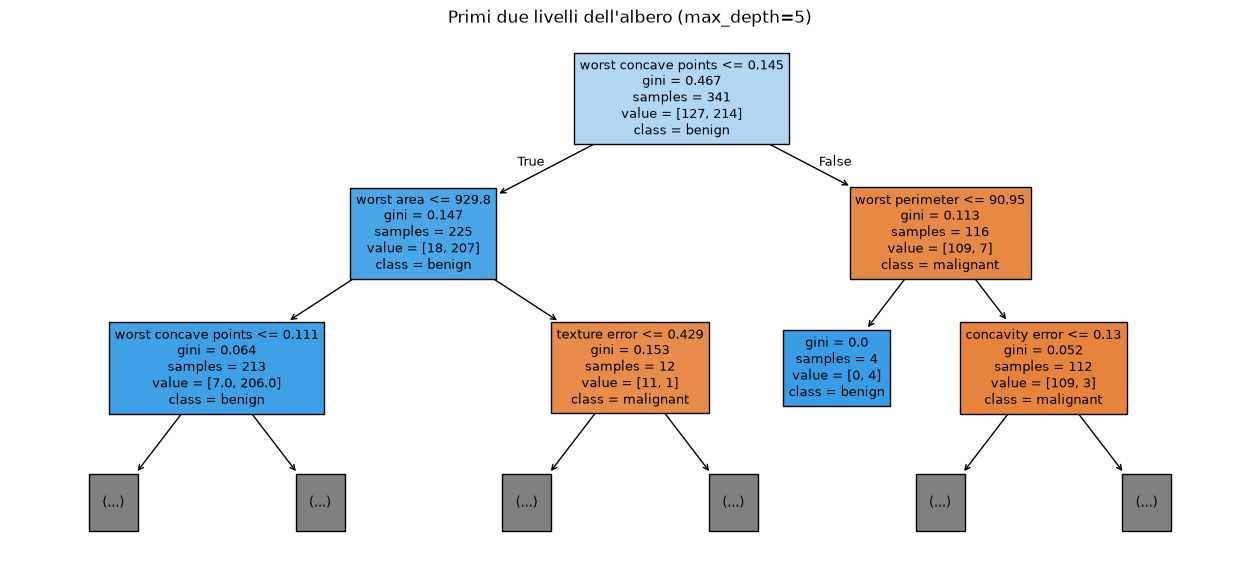

In [23]:
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    albero,
    feature_names=list(X.columns),
    class_names=list(d.target_names),  # ordine: 0 = malignant, 1 = benign
    filled=True,
    max_depth=2,
    fontsize=9,
    ax=ax,
)
ax.set_title(f"Primi due livelli dell'albero (max_depth={PROFONDITA_SCELTA})")
plt.show()

### 8.4 Indice di Gini della radice, calcolato a mano

L'indice di **Gini** misura quanto un nodo è «misto»: 0 se contiene una sola classe, 0.5 se le due classi sono in parti uguali. Per il nodo radice, con $p_0$ e $p_1$ le frazioni delle due classi nel training:

$$\text{Gini} = 1 - (p_0^2 + p_1^2)$$

In [24]:
# Frazioni delle due classi nel training (il nodo radice contiene tutto il training)
frazioni = y_train.value_counts(normalize=True)
gini_manuale = 1 - (frazioni ** 2).sum()

print(f"Gini calcolato a mano:                  {gini_manuale:.6f}")
print(f"Gini del nodo radice (tree_.impurity[0]): {albero.tree_.impurity[0]:.6f}")
assert np.isclose(gini_manuale, albero.tree_.impurity[0])  # devono coincidere

Gini calcolato a mano:                  0.467454
Gini del nodo radice (tree_.impurity[0]): 0.467454


### 8.5 Lo scaling non cambia le decisioni dell'albero

In [25]:
# Stesso albero, addestrato però sui dati scalati
albero_sc = DecisionTreeClassifier(max_depth=PROFONDITA_SCELTA, random_state=RANDOM_STATE)
albero_sc.fit(X_train_sc, y_train)

pred_raw = albero.predict(X_val)
pred_sc = albero_sc.predict(X_val_sc)
print("Accuratezza validation (non scalato):", round(accuracy_score(y_val, pred_raw), 3))
print("Accuratezza validation (scalato):    ", round(accuracy_score(y_val, pred_sc), 3))
print("Previsioni identiche:", np.array_equal(pred_raw, pred_sc))

Accuratezza validation (non scalato): 0.956
Accuratezza validation (scalato):     0.956
Previsioni identiche: True


Le previsioni sono identiche. Lo scaling cambia i numeri delle soglie (ad esempio `worst area` ≤ 929.8 diventa una soglia sui valori standardizzati), ma non cambia quali pazienti finiscono da una parte o dall'altra della soglia. Per questo l'albero non ha bisogno dello scaling.

## Punto 9 — Valutazione finale sul test set

Ora, e solo ora, usiamo il test set. Riaddestriamo i modelli scelti su **training + validation** insieme, così da usare più dati (455 pazienti):
- KNN con `k = 3` (scelto al punto 7), con lo scaler rifatto sul nuovo training;
- albero con `max_depth = 5` (scelto al punto 8);
- il dummy, come riferimento.

### 9.1 Riaddestramento e previsioni sul test

In [26]:
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])

# Lo scaler viene rifatto solo sul nuovo training: il test resta fuori dal fit
scaler_finale = StandardScaler().fit(X_trval)
nome_knn = f"KNN (k={k_migliore})"
knn_finale = KNeighborsClassifier(n_neighbors=k_migliore).fit(scaler_finale.transform(X_trval), y_trval)
albero_finale = DecisionTreeClassifier(max_depth=PROFONDITA_SCELTA, random_state=RANDOM_STATE)
albero_finale.fit(X_trval, y_trval)
dummy_finale = DummyClassifier(strategy="most_frequent").fit(X_trval, y_trval)

# Il KNN lavora su dati scalati; albero e dummy su quelli originali
previsioni = {
    "Dummy": dummy_finale.predict(X_test),
    nome_knn: knn_finale.predict(scaler_finale.transform(X_test)),
    f"Albero (max_depth={PROFONDITA_SCELTA})": albero_finale.predict(X_test),
}
print("Pazienti usati per il riaddestramento:", len(X_trval))
print("Pazienti nel test set:", len(X_test))

Pazienti usati per il riaddestramento: 455
Pazienti nel test set: 114


### 9.2 Accuratezza, precision, recall e F1 (classe positiva = maligno)

- **Precision:** tra i pazienti che il modello dichiara maligni, quanti lo sono davvero.
- **Recall:** tra i maligni veri, quanti il modello ne trova. È la metrica più importante qui, perché un maligno non riconosciuto è l'errore più grave.
- **F1:** media armonica di precision e recall.

In [27]:
righe = []
for nome, pred in previsioni.items():
    righe.append({
        "modello": nome,
        "accuratezza": accuracy_score(y_test, pred),
        "precision (maligni)": precision_score(y_test, pred, pos_label=0, zero_division=0),
        "recall (maligni)": recall_score(y_test, pred, pos_label=0, zero_division=0),
        "F1 (maligni)": f1_score(y_test, pred, pos_label=0, zero_division=0),
    })
tabella_finale = pd.DataFrame(righe).set_index("modello")
tabella_finale.round(3)

,accuratezza,precision (maligni),recall (maligni),F1 (maligni)
modello,,,,
Dummy,0.632,0.000,0.000,0.000
KNN (k=3),0.982,1.000,0.952,0.976
Albero (max_depth=5),0.921,0.867,0.929,0.897


### 9.2b `classification_report` con i nomi delle classi

In [28]:
for nome, pred in previsioni.items():
    print(f"=== {nome} ===")
    print(classification_report(
        y_test, pred, labels=[0, 1], target_names=["maligno", "benigno"], zero_division=0
    ))

=== Dummy ===
              precision    recall  f1-score   support

     maligno       0.00      0.00      0.00        42
     benigno       0.63      1.00      0.77        72

    accuracy                           0.63       114
   macro avg       0.32      0.50      0.39       114
weighted avg       0.40      0.63      0.49       114

=== KNN (k=3) ===
              precision    recall  f1-score   support

     maligno       1.00      0.95      0.98        42
     benigno       0.97      1.00      0.99        72

    accuracy                           0.98       114
   macro avg       0.99      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

=== Albero (max_depth=5) ===
              precision    recall  f1-score   support

     maligno       0.87      0.93      0.90        42
     benigno       0.96      0.92      0.94        72

    accuracy                           0.92       114
   macro avg       0.91      0.92      0.92       114
weighted avg 

### 9.3 Matrici di confusione

La matrice di confusione mostra, per ogni classe vera, quante volte il modello ha previsto ciascuna classe. Righe = classe vera, colonne = classe prevista.

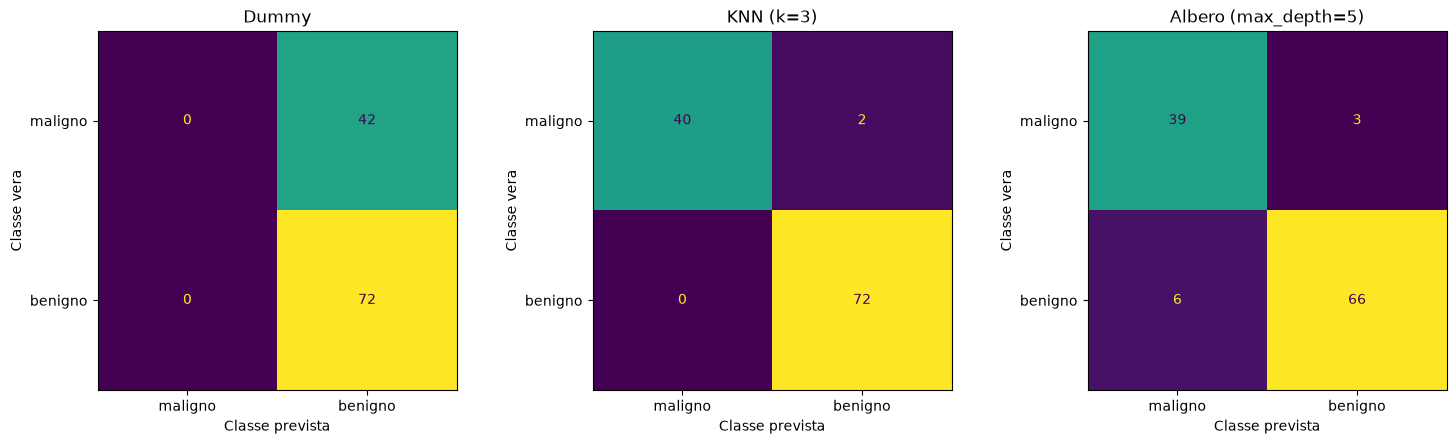

In [29]:
fig, assi = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (nome, pred) in zip(assi, previsioni.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, labels=[0, 1], display_labels=["maligno", "benigno"], ax=ax, colorbar=False
    )
    ax.set_title(nome)
    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe vera")
plt.tight_layout()
plt.show()

### 9.4 TP, TN, FP, FN calcolati a mano (KNN)

Con la classe positiva = **maligno** (0):
- **TP** (vero positivo): maligno previsto come maligno;
- **FN** (falso negativo): maligno previsto come benigno, **il caso più grave**;
- **FP** (falso positivo): benigno previsto come maligno;
- **TN** (vero negativo): benigno previsto come benigno.

Quindi precision = TP / (TP + FP) e recall = TP / (TP + FN).

In [30]:
# confusion_matrix con labels=[0, 1]: righe = classe vera, colonne = classe prevista
cm = confusion_matrix(y_test, previsioni[nome_knn], labels=[0, 1])

TP = cm[0, 0]  # maligno -> maligno
FN = cm[0, 1]  # maligno -> benigno
FP = cm[1, 0]  # benigno -> maligno
TN = cm[1, 1]  # benigno -> benigno
print(f"TP = {TP}   FN = {FN}   FP = {FP}   TN = {TN}")

precision_a_mano = TP / (TP + FP)
recall_a_mano = TP / (TP + FN)
print(f"\nPrecision a mano: {precision_a_mano:.4f}   sklearn: {tabella_finale.loc[nome_knn, 'precision (maligni)']:.4f}")
print(f"Recall a mano:    {recall_a_mano:.4f}   sklearn: {tabella_finale.loc[nome_knn, 'recall (maligni)']:.4f}")

assert np.isclose(precision_a_mano, tabella_finale.loc[nome_knn, "precision (maligni)"])
assert np.isclose(recall_a_mano, tabella_finale.loc[nome_knn, "recall (maligni)"])

TP = 40   FN = 2   FP = 0   TN = 72

Precision a mano: 1.0000   sklearn: 1.0000
Recall a mano:    0.9524   sklearn: 0.9524


### 9.5 Scelta del modello finale

Dalla tabella:
- **Dummy:** non trova nessun maligno (recall 0): escluso.
- **Albero:** recall 92.9%, precision 86.7%. Sbaglia **3** maligni (FN) e segnala **6** benigni come maligni (FP).
- **KNN (k=3):** recall 95.2%, precision 100%. Sbaglia **2** maligni (FN) e nessun benigno.

Il criterio clinico dice che i falsi negativi sono più gravi dei falsi positivi: un falso positivo porta a un approfondimento inutile, un falso negativo fa sfuggire un tumore. Il **KNN con k = 3** ha il numero minore di falsi negativi e in più non produce falsi positivi. L'albero ha un vantaggio: è leggibile come regole, utile per spiegare le decisioni al team clinico. Per la stima finale privilegiamo però la recall.

*Nota onesta:* il confronto tra i due modelli è stato fatto sul test set, usato una sola volta per questo. Con 114 pazienti la differenza di due-tre casi non è statisticamente solida: è un argomento di prudenza, non una prova definitiva.

### 9.6 Stima da comunicare alla direzione

La stima onesta è quella su dati che non hanno mai toccato né il training né la scelta di k e della profondità. Calcoliamo anche un **intervallo di confidenza**, perché con 42 maligni nel test una singola percentuale non basta a dire quanto è precisa.

In [31]:
def intervallo_wilson(successi, n, z=1.96):
    # Intervallo di confidenza al 95% per una proporzione (formula di Wilson)
    p = successi / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margine = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - margine, centro + margine

maligni_nel_test = TP + FN  # tutti i maligni del test set
recall_finale = TP / maligni_nel_test
inf, sup = intervallo_wilson(TP, maligni_nel_test)

print(f"Maligni individuati: {TP} su {maligni_nel_test}")
print(f"Recall sui maligni: {recall_finale:.1%}")
print(f"Intervallo di confidenza al 95%: {inf:.1%} – {sup:.1%}")

Maligni individuati: 40 su 42
Recall sui maligni: 95.2%
Intervallo di confidenza al 95%: 84.2% – 98.7%


**Stima da riportare alla direzione:**

> Il sistema individua circa il **95%** dei tumori maligni (40 su 42 nel test set), con **precisione del 100%**: quando segnala un maligno, nel test ha sempre avuto ragione. Il valore reale della recall è però incerto: con i dati disponibili l'intervallo di confidenza al 95% va da circa l'84% al 99%. Il modello è uno strumento di **supporto** allo screening, non sostituisce la valutazione clinica; i 2 maligni sfuggiti restano il rischio principale.

**Perché la stima è affidabile (e quali limiti ha):**
- è calcolata su pazienti mai usati per addestrare né per scegliere k, profondità o scaler;
- il test è stato usato una sola volta, a fine lavorazione;
- il campione è piccolo, quindi l'intervallo è ampio: per restringerlo servirebbero più dati o una cross-validation (vedi il bonus 2 dell'esercizio);
- il dataset è storico e di origine nota: prima di un uso in ospedale servirebbe una validazione su pazienti dell'ospedale stesso.

## Riepilogo

| Punto | Risultato chiave |
| --- | --- |
| 2 | 569 pazienti, 30 feature, classi circa 63% benigni / 37% maligni |
| 4 | Baseline (dummy): accuratezza ~62%, recall maligni 0% |
| 5 → 6 | KNN senza scaling ~93%; con scaling ~96% |
| 7 | k scelto = 3 (sul validation) |
| 8 | Albero scelto con profondità 5 (accuratezza validation ~96%) |
| 9 | Test: KNN (k=3) recall ~95%, precision 100%, 2 falsi negativi |

**Idee chiave del notebook:** training, validation e test hanno ruoli diversi; lo scaler si adatta solo al training; l'accuratezza da sola può ingannare su dati sbilanciati; la scelta dei parametri si fa sul validation, la stima finale sul test.

## Bonus

Le tre domande facoltative dell'esercizio. Il test set non viene mai usato qui: lavoriamo solo con training e validation.

### Bonus 1 — KNN pesato per distanza

Con `weights="uniform"` (quello usato finora) tutti i k vicini contano allo stesso modo. Con `weights="distance"` i vicini più vicini pesano di più, proporzionalmente a 1/distanza.

In [32]:
# Confronto tra KNN uniforme (voto semplice) e KNN pesato per distanza, su più valori di k
print(f"{'k':>3} | {'uniform train':>13} {'uniform val':>11} | {'distance train':>14} {'distance val':>12}")
for k in [3, 5, 11, 21]:
    uniforme = KNeighborsClassifier(n_neighbors=k).fit(X_train_sc, y_train)
    pesato = KNeighborsClassifier(n_neighbors=k, weights="distance").fit(X_train_sc, y_train)
    print(f"{k:>3} | {uniforme.score(X_train_sc, y_train):>13.3f} {uniforme.score(X_val_sc, y_val):>11.3f} | "
          f"{pesato.score(X_train_sc, y_train):>14.3f} {pesato.score(X_val_sc, y_val):>12.3f}")

  k | uniform train uniform val | distance train distance val


  3 |         0.977       0.965 |          1.000        0.965
  5 |         0.974       0.956 |          1.000        0.956
 11 |         0.971       0.939 |          1.000        0.939
 21 |         0.962       0.930 |          1.000        0.930


**Commento.** Sul training il KNN pesato arriva sempre al 100%: ogni paziente ha distanza 0 da se stesso, quindi riceve un peso enorme e vince il proprio voto. È memorizzazione, non generalizzazione. Sul validation, invece, i due modelli danno gli stessi risultati: per questo dataset la ponderazione non porta vantaggi. La lezione da tenere: l'accuratezza di training può essere ingannevole con il KNN.

### Bonus 2 — Stabilità della scelta di k

Abbiamo scelto k = 3 su un solo split training/validation. Quanto è affidabile questa scelta? Ripetiamo la curva di validation con 5 valori diversi di `random_state` per lo split. Il test set resta fuori, e usiamo `X_temp` (l'80% del punto 3).

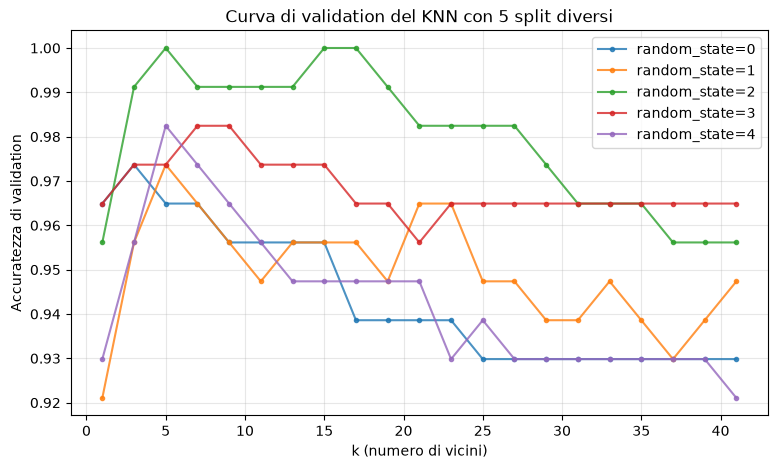

   k migliore  accuratezza migliore  accuratezza peggiore
0           3                 0.974                 0.930
1           5                 0.974                 0.921
2           5                 1.000                 0.956
3           7                 0.982                 0.956
4           5                 0.982                 0.921


In [33]:
curve = {}  # per ogni seed, l'accuratezza di validation per ciascun k dispari
for seed in [0, 1, 2, 3, 4]:
    X_tr_s, X_val_s, y_tr_s, y_val_s = train_test_split(
        X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=seed
    )
    scaler_s = StandardScaler().fit(X_tr_s)  # lo scaler si rifà per ogni split, solo sul suo training
    accuratezze = []
    for k in range(1, 42, 2):
        modello = KNeighborsClassifier(n_neighbors=k).fit(scaler_s.transform(X_tr_s), y_tr_s)
        accuratezze.append(modello.score(scaler_s.transform(X_val_s), y_val_s))
    curve[seed] = accuratezze

ks = list(range(1, 42, 2))
fig, ax = plt.subplots(figsize=(9, 5))
for seed, accuratezze in curve.items():
    ax.plot(ks, accuratezze, marker="o", markersize=3, alpha=0.8, label=f"random_state={seed}")
ax.set_title("Curva di validation del KNN con 5 split diversi")
ax.set_xlabel("k (numero di vicini)")
ax.set_ylabel("Accuratezza di validation")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

riepilogo = pd.DataFrame({
    "k migliore": {seed: ks[int(np.argmax(acc))] for seed, acc in curve.items()},
    "accuratezza migliore": {seed: max(acc) for seed, acc in curve.items()},
    "accuratezza peggiore": {seed: min(acc) for seed, acc in curve.items()},
})
print(riepilogo.round(3))

**Commento.** Il k «migliore» cambia da split a split: è 3, 5 o 7. Anche l'accuratezza varia parecchio, da circa 0.92 a 1.00 a seconda dello split, e la differenza tra il k migliore e il peggiore di uno stesso split può superare i tre punti percentuali. Quindi la scelta di k = 3 sul solo split del punto 7 dipende in parte dalla fortuna nello split.

Questo suggerisce di non fidarsi di un singolo split. La soluzione è la **cross-validation**: dividere il training in più parti (fold), usare ognuna a turno come validation e fare la media dei risultati. Ogni paziente viene usato per la validazione una sola volta, e la stima diventa più stabile.

### Bonus 3 — Confini curvi con `make_moons`

`make_moons` genera due «lune» intrecciate: le due classi non si separano con una retta, e il confine di decisione è curvo. Confrontiamo l'albero e il KNN con `DecisionBoundaryDisplay`, che colora le regioni di decisione del modello.

Le due feature hanno la stessa scala, quindi qui lo scaling non serve.

Albero (max_depth=5): accuratezza validation = 0.880
KNN (k=5): accuratezza validation = 0.900


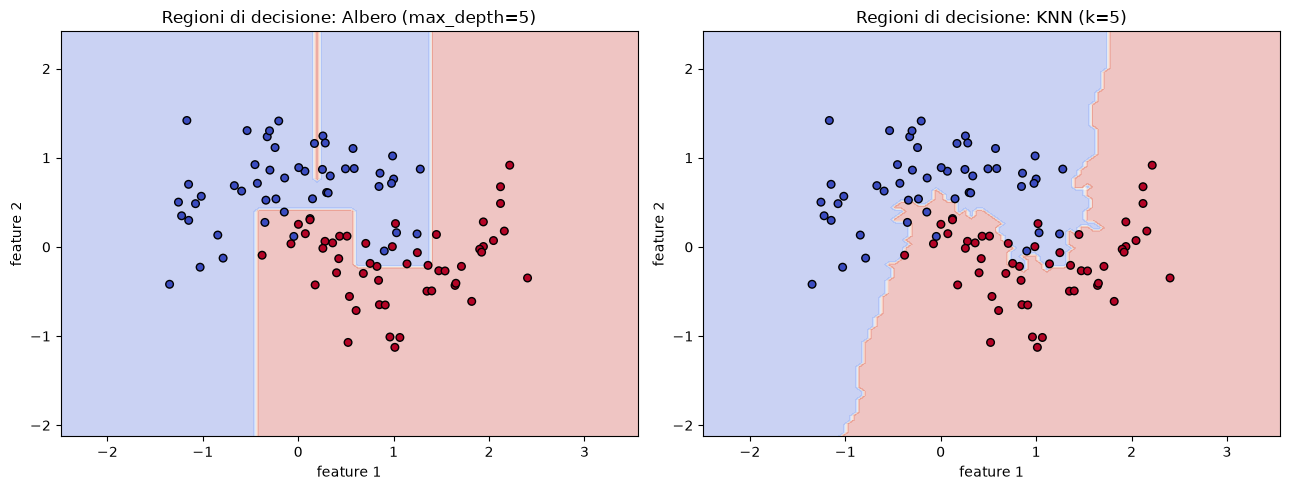

In [34]:
from sklearn.datasets import make_moons
from sklearn.inspection import DecisionBoundaryDisplay

# 400 punti, con rumore per rendere il problema meno banale
X_moon, y_moon = make_moons(n_samples=400, noise=0.3, random_state=RANDOM_STATE)
Xm_train, Xm_val, ym_train, ym_val = train_test_split(
    X_moon, y_moon, test_size=0.25, stratify=y_moon, random_state=RANDOM_STATE
)

modelli_moon = {
    "Albero (max_depth=5)": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
}

fig, assi = plt.subplots(1, 2, figsize=(13, 5))
for ax, (nome, modello) in zip(assi, modelli_moon.items()):
    modello.fit(Xm_train, ym_train)
    print(f"{nome}: accuratezza validation = {modello.score(Xm_val, ym_val):.3f}")

    DecisionBoundaryDisplay.from_estimator(
        modello, X_moon, response_method="predict", alpha=0.3, ax=ax, cmap="coolwarm"
    )
    ax.scatter(Xm_val[:, 0], Xm_val[:, 1], c=ym_val, cmap="coolwarm", edgecolor="k", s=30)
    ax.set_title(f"Regioni di decisione: {nome}")
    ax.set_xlabel("feature 1")
    ax.set_ylabel("feature 2")
plt.tight_layout()
plt.show()

**Commento.** Le regioni mostrano come lavorano i due modelli:
- l'**albero** divide lo spazio con linee orizzontali e verticali, quindi il confine è una «scala» di rettangoli che approssima la curva;
- il **KNN** segue la forma delle lune: il confine si piega attorno ai punti, senza vincoli di direzione.

Sul validation il KNN è un po' più accurato, ma la differenza è di due punti percentuali su 100 pazienti: è troppo poco per concludere che sia sempre migliore. La lezione è che il modello giusto dipende dalla forma del problema: con confini curvi e dati non troppo rumorosi, il KNN è un candidato naturale; con regole che si leggono come soglie su poche feature, l'albero è più interpretabile.